# Agrupamiento de países por indicadores socioeconómicos

Segmentación de 167 países según siete indicadores (exportaciones, importaciones y gasto en salud como porcentaje del PIB, ingreso por persona, inflación, expectativa de vida y PIB per cápita) con K-means y clustering jerárquico, y lectura de los ejes principales de variación con PCA.

Datos: [Unsupervised Learning on Country Data](https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data) (Kaggle), descargados con `kagglehub`; se usan siete de sus nueve variables.

## 1. Datos y valores atípicos

In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

ruta = kagglehub.dataset_download('rohan0301/unsupervised-learning-on-country-data')
df = pd.read_csv(f'{ruta}/Country-data.csv').rename(columns={
    'country': 'país', 'exports': 'exportaciones', 'health': 'salud', 'imports': 'importaciones',
    'income': 'ingresos', 'inflation': 'inflacion', 'life_expec': 'expectativa'})
df = df[['país', 'exportaciones', 'salud', 'importaciones', 'ingresos', 'inflacion', 'expectativa', 'gdpp']]

print(f'{len(df)} países, {df.isnull().sum().sum()} valores faltantes')
display(df.head())

167 países, 0 valores faltantes


,país,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
0,Afghanistan,10.0,7.58,44.9,1610,9.44,56.2,553
1,Albania,28.0,6.55,48.6,9930,4.49,76.3,4090
2,Algeria,38.4,4.17,31.4,12900,16.10,76.5,4460
3,Angola,62.3,2.85,42.9,5900,22.40,60.1,3530
4,Antigua and Barbuda,45.5,6.03,58.9,19100,1.44,76.8,12200



--- Estadísticas Descriptivas ---


,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,12964.155689
std,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,18328.704809
min,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,231.000000
25%,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1330.000000
50%,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,4660.000000
75%,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,14050.000000
max,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,105000.000000


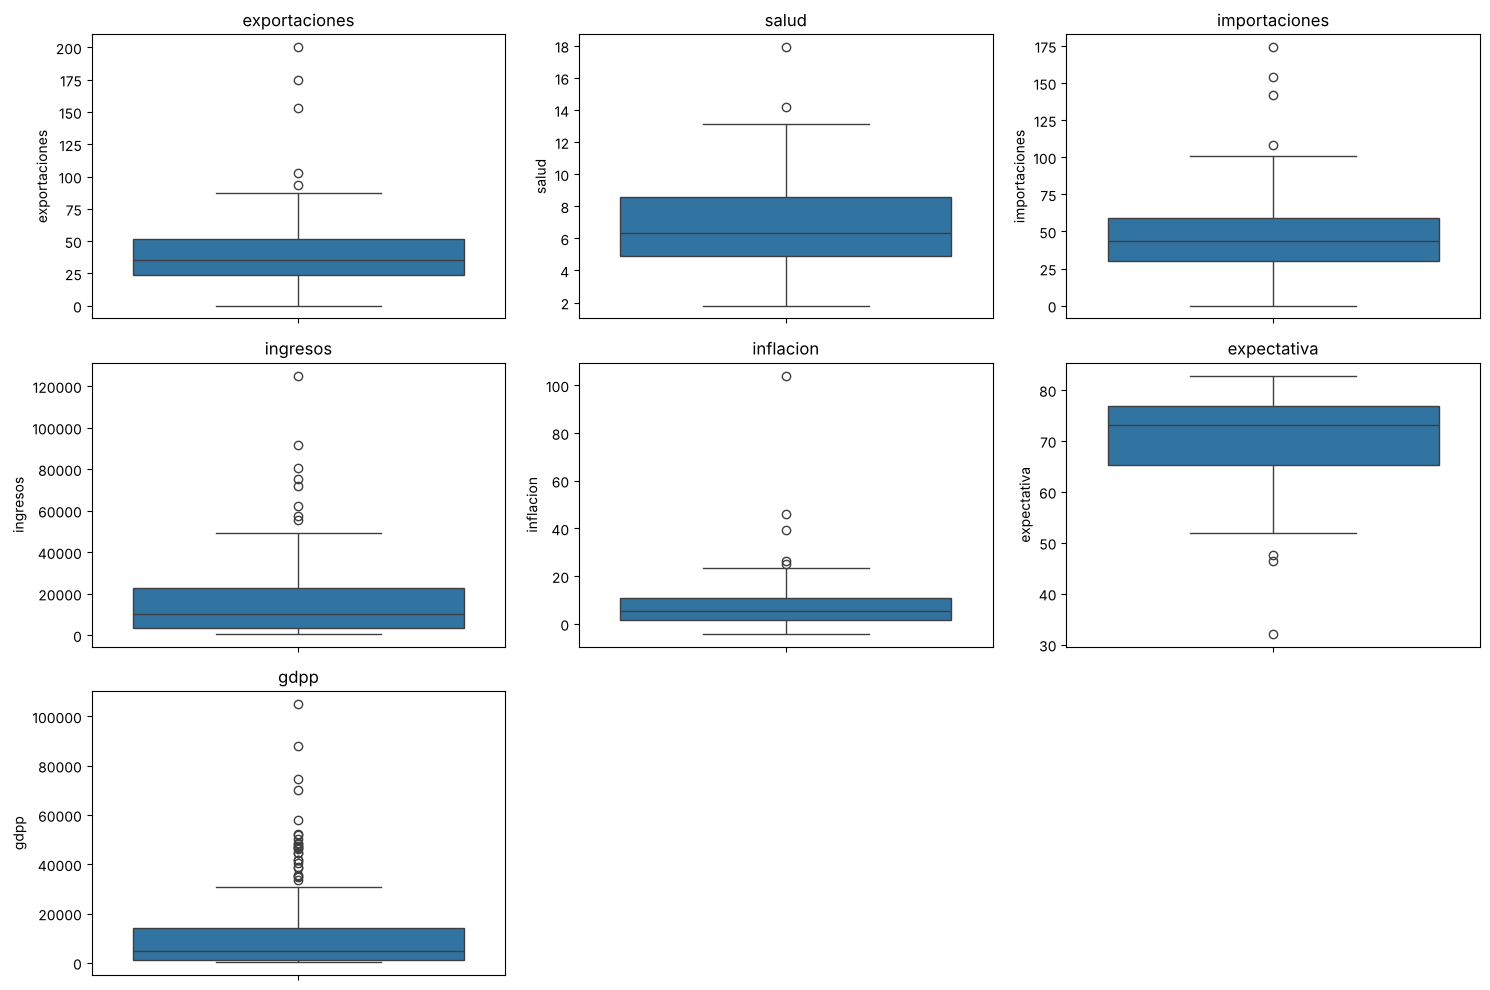

In [2]:
# Limpieza de datos: Manejo de valores nulos y duplicados
# Revisión de duplicados
duplicates = df.duplicated().sum()
if duplicates > 0:
    print(f"REliminando {duplicates} filas duplicadas.")
    df = df.drop_duplicates()

print("\n--- Estadísticas Descriptivas ---")
display(df.describe())

# Detección de atípicos (outliers) usando Boxplots para columnas numéricas
numerical_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [3]:
# Investigando atípicos altos para darles contexto
print("--- Países con inflación alta (> 50%) ---")
display(df[df['inflacion'] > 50])

print("\n--- Países con exportaciones altas (> 100%) ---")
display(df[df['exportaciones'] > 100])

print("\n--- Países con un GDPP muy alto (Top 5) ---")
display(df.nlargest(5, 'gdpp'))

# Revisando posibles errores: Valores bajos en expectativa de vida
print("\n--- Países con expectativa de vida baja (< 45) ---")
display(df[df['expectativa'] < 45])

--- Países con inflación alta (> 50%) ---


,país,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
113,Nigeria,25.3,5.07,17.4,5150,104.0,60.5,2330



--- Países con exportaciones altas (> 100%) ---


,país,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
73,Ireland,103.0,9.19,86.5,45700,-3.220,80.4,48700
91,Luxembourg,175.0,7.77,142.0,91700,3.620,81.3,105000
98,Malta,153.0,8.65,154.0,28300,3.830,80.3,21100
133,Singapore,200.0,3.96,174.0,72100,-0.046,82.7,46600



--- Países con un GDPP muy alto (Top 5) ---


,país,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
91,Luxembourg,175.0,7.77,142.0,91700,3.620,81.3,105000
114,Norway,39.7,9.48,28.5,62300,5.950,81.0,87800
145,Switzerland,64.0,11.50,53.3,55500,0.317,82.2,74600
123,Qatar,62.3,1.81,23.8,125000,6.980,79.5,70300
44,Denmark,50.5,11.40,43.6,44000,3.220,79.5,58000



--- Países con expectativa de vida baja (< 45) ---


,país,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
66,Haiti,15.3,6.91,64.7,1500,5.45,32.1,662


La base no tiene valores faltantes ni filas repetidas. No encontramos problemas graves de celdas vacías ni filas repetidas, así que no hubo necesidad de eliminar registros masivamente.

Los "Atípicos" que en realidad son reales: Al graficar, salieron valores extremos que parecían errores de tipeo, pero al investigar los países, nos dimos cuenta de que son sus realidades socioeconómicas:

- Exportaciones/Importaciones altísimas (>100%): Países pequeños como Singapur o Malta mueven más del 100% de su PIB. Esto pasa porque son "economías de tránsito" (importan mucho para volver a exportar).

- Expectativa de vida muy baja (32 años): Corresponde a Haití. Tristemente no está mal digitado, es el reflejo de la catástrofe humanitaria (probablemente los datos sean del año del terremoto de 2010).

- Inflación extrema (104%): Es el caso de Nigeria. Parece falso, pero el país sí ha pasado por crisis brutales de hiperinflación. [pagina de la info](https://tradingeconomics.com/nigeria/inflation-cpi)

Aunque estos valores son reales y no se pueden eliminar, es necesario transformalos ya que uno de los futuros algoritmos como lo es el k-means, es muy sencible a los datos atipicos y podría crear grupos individuales para estos datos. Por lo tanto, tomamos la desición de limitarlos hasta rango interquartil.

In [4]:
# --- NUEVO: CORRECCIÓN DE ATÍPICOS ---
# Dado que K-means es sensible a atípicos, aplicaremos un límite usando el Rango Intercuartílico (IQR) para suavizar los extremos sin eliminar los países.

df_cleaned = df.copy()

for col in numerical_cols:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    # Reemplazar valores por los límites calculados (Capping)
    df_cleaned[col] = np.where(df_cleaned[col] > limite_superior, limite_superior, df_cleaned[col])
    df_cleaned[col] = np.where(df_cleaned[col] < limite_inferior, limite_inferior, df_cleaned[col])

In [5]:
if 'país' in df_cleaned.columns:
    df_cleaned = df_cleaned.set_index('país')

print("--- DataFrame listo para modelos  ---")
display(df_cleaned.head())

--- DataFrame listo para modelos  ---


,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
país,,,,,,,
Afghanistan,10.0,7.58,44.9,1610.0,9.44,56.2,553.0
Albania,28.0,6.55,48.6,9930.0,4.49,76.3,4090.0
Algeria,38.4,4.17,31.4,12900.0,16.10,76.5,4460.0
Angola,62.3,2.85,42.9,5900.0,22.40,60.1,3530.0
Antigua and Barbuda,45.5,6.03,58.9,19100.0,1.44,76.8,12200.0


## 2. Distribuciones y relaciones


--- Estadísticas Descriptivas ---


,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
count,167.00,167.00,167.00,167.00,167.00,167.00,167.00
mean,39.54,6.79,45.86,15921.57,7.07,70.66,10351.28
std,21.30,2.67,20.34,15207.20,6.70,8.52,11612.04
min,0.11,1.81,0.07,609.00,-4.21,48.05,231.00
25%,23.80,4.92,30.20,3355.00,1.81,65.30,1330.00
50%,35.00,6.32,43.30,9960.00,5.39,73.10,4660.00
75%,51.35,8.60,58.75,22800.00,10.75,76.80,14050.00
max,92.67,14.12,101.58,51967.50,24.16,82.80,33130.00


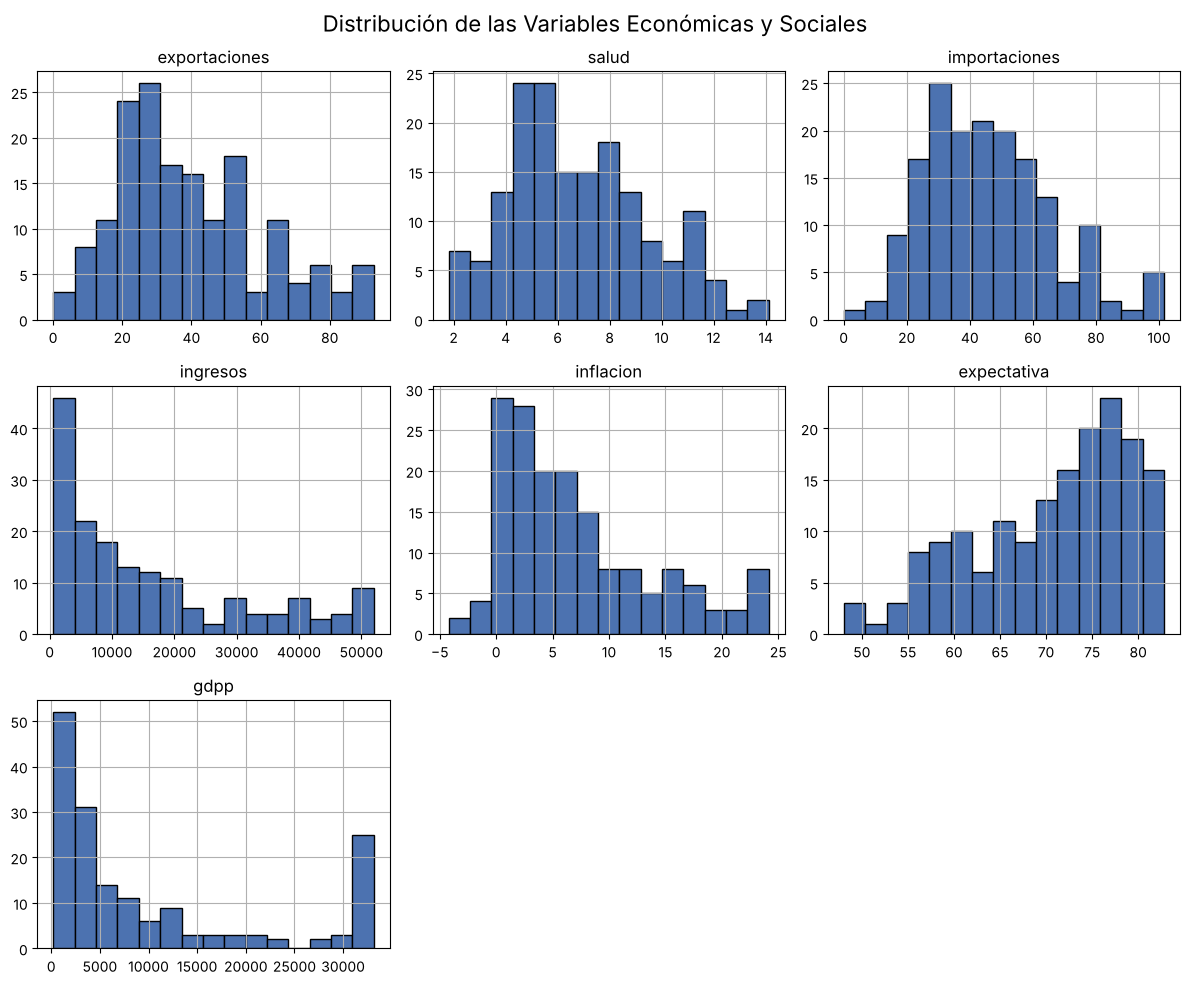

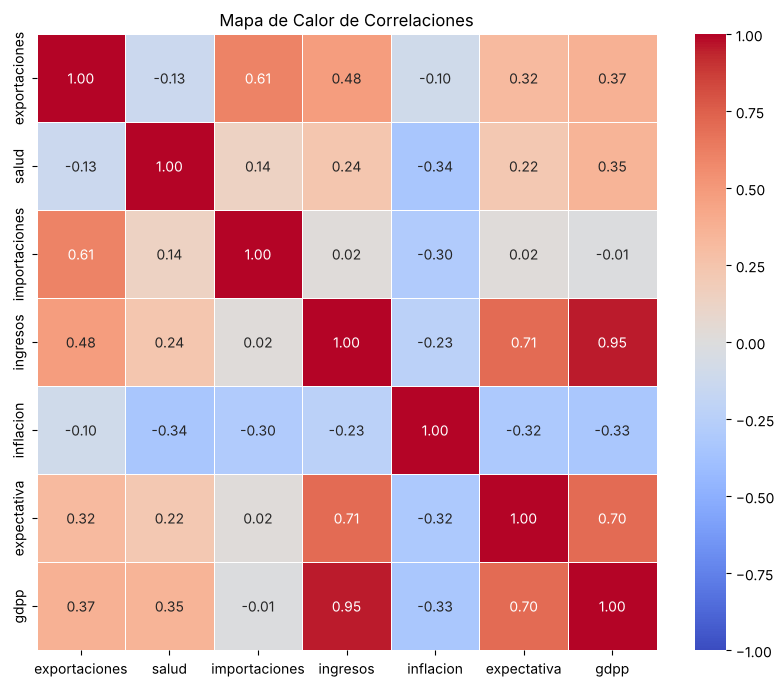

In [6]:
# --- ESTADÍSTICAS Y GRÁFICOS ---

# 1. Estadísticas descriptivas finales
print("\n--- Estadísticas Descriptivas ---")
display(df_cleaned.describe().round(2))

# 2. Histogramas para analizar la distribución
df_cleaned.hist(bins=15, figsize=(12, 10), color='#4C72B0', edgecolor='black')
plt.suptitle('Distribución de las Variables Económicas y Sociales', fontsize=16)
plt.tight_layout()
plt.show()

# 3. Mapa de calor de correlaciones
plt.figure(figsize=(10, 8))
sns.heatmap(df_cleaned.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de Calor de Correlaciones')
plt.show()

**Distribuciones (después de acotar los extremos):** ingresos, PIB per cápita e inflación se concentran a la izquierda, con la mayoría de países en valores bajos y una cola de países ricos o con inflación alta. La expectativa de vida muestra el patrón opuesto: la mayoría está entre 70 y 80 años, con una cola hacia valores bajos.

**Correlaciones:**
- Ingresos y PIB per cápita están casi perfectamente correlacionados (0,95): miden prácticamente lo mismo.
- Exportaciones e importaciones tienen una relación positiva moderada (0,61), típica de economías abiertas.
- La expectativa de vida se asocia con el PIB per cápita (0,70) y los ingresos (0,71).
- La inflación tiene correlaciones negativas débiles con el resto, por ejemplo −0,32 con la expectativa de vida.

--- Top 10 Países con Mayores Ingresos ---
país
Qatar                   125000
Luxembourg               91700
Brunei                   80600
Kuwait                   75200
Singapore                72100
Norway                   62300
United Arab Emirates     57600
Switzerland              55500
United States            49400
Ireland                  45700
Name: ingresos, dtype: int64

--- Top 10 Países con Mayor Expectativa de Vida ---
país
Japan          82.8
Singapore      82.7
Switzerland    82.2
Australia      82.0
Iceland        82.0
Spain          81.9
Italy          81.7
Sweden         81.5
France         81.4
Israel         81.4
Name: expectativa, dtype: float64


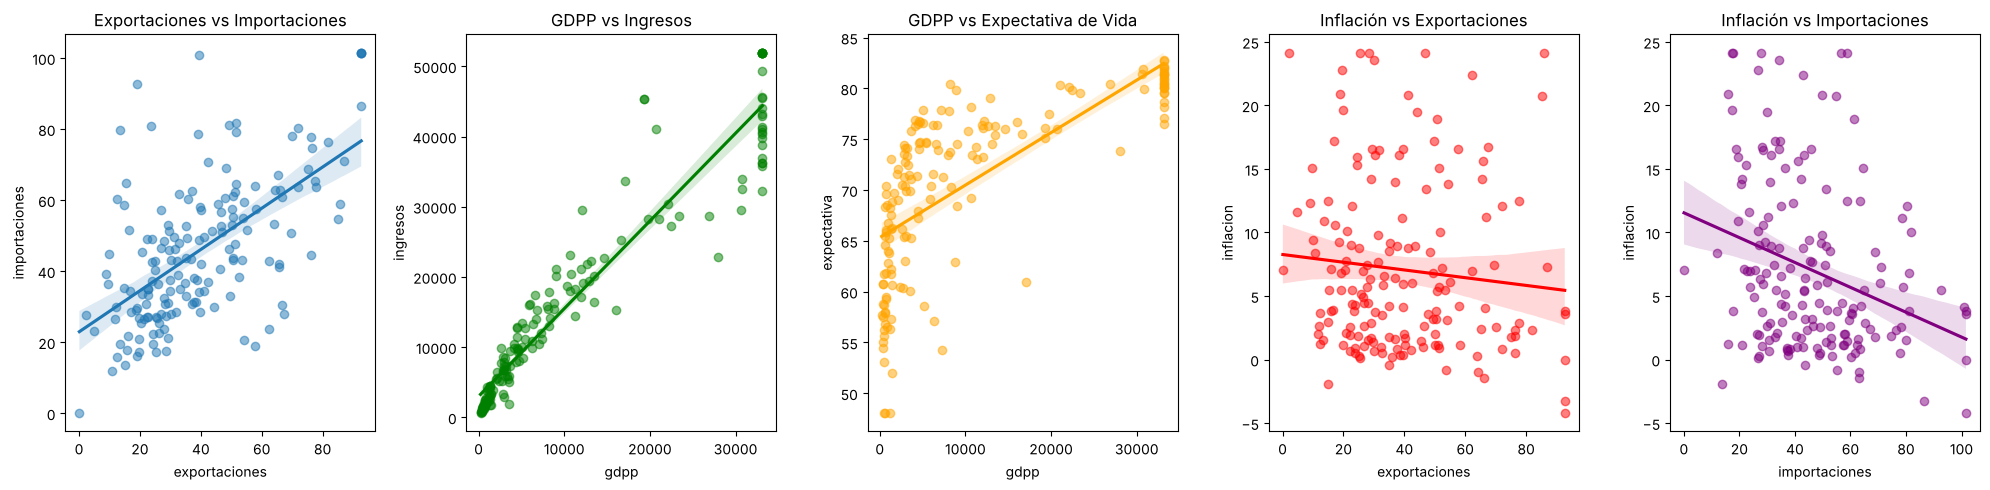

In [7]:
# --- CRUCE DE VARIABLES ---

# 1. Países con mayores ingresos promedio
top_ingresos = df.set_index('país')['ingresos'].nlargest(10)  # valores originales, sin el recorte
print("--- Top 10 Países con Mayores Ingresos ---")
print(top_ingresos)

# 2. Países con expectativa de vida más alta
top_vida = df.set_index('país')['expectativa'].nlargest(10)
print("\n--- Top 10 Países con Mayor Expectativa de Vida ---")
print(top_vida)

# 3. Gráficos para analizar relaciones (Cruces)
plt.figure(figsize=(20, 5)) # Aumentar el tamaño para acomodar más gráficos

# Relación Exportaciones vs Importaciones
plt.subplot(1, 5, 1) # Cambiar el número de subplots
sns.regplot(x=df_cleaned['exportaciones'], y=df_cleaned['importaciones'], scatter_kws={'alpha':0.5})
plt.title('Exportaciones vs Importaciones')

# Relación GDPP vs Ingresos
plt.subplot(1, 5, 2)
sns.regplot(x=df_cleaned['gdpp'], y=df_cleaned['ingresos'], color='green', scatter_kws={'alpha':0.5})
plt.title('GDPP vs Ingresos')

# Relación GDPP vs Expectativa
plt.subplot(1, 5, 3)
sns.regplot(x=df_cleaned['gdpp'], y=df_cleaned['expectativa'], color='orange', scatter_kws={'alpha':0.5})
plt.title('GDPP vs Expectativa de Vida')

# NUEVO: Relación Inflación vs Exportaciones
plt.subplot(1, 5, 4)
sns.regplot(x=df_cleaned['exportaciones'], y=df_cleaned['inflacion'], color='red', scatter_kws={'alpha':0.5})
plt.title('Inflación vs Exportaciones')

# NUEVO: Relación Inflación vs Importaciones
plt.subplot(1, 5, 5)
sns.regplot(x=df_cleaned['importaciones'], y=df_cleaned['inflacion'], color='purple', scatter_kws={'alpha':0.5})
plt.title('Inflación vs Importaciones')

plt.tight_layout()
plt.show()

**Mayores ingresos:** los primeros lugares son exportadores de petróleo y centros financieros con poblaciones pequeñas (Qatar, Luxemburgo, Brunéi, Kuwait, Singapur, Noruega). Por el recorte de atípicos, en la tabla acotada estos países quedan empatados en el límite superior; por eso el ranking usa los valores originales.

**Mayor expectativa de vida:** Japón, Singapur, Suiza, Australia e Islandia. Son países ricos, pero no coinciden con los de mayor ingreso: el nivel de vida no depende solo del ingreso.

Los diagramas de dispersión confirman lo que muestran las correlaciones: la relación entre PIB per cápita y expectativa de vida es creciente pero se aplana en los países ricos, y la inflación no muestra una tendencia clara frente al comercio exterior.

## 3. K-means

Las variables se estandarizan para que ninguna domine por su escala. Para elegir el número de grupos se revisan la inercia (método del codo) y el coeficiente de silueta entre 2 y 8 grupos, y se comparan las segmentaciones con k = 3, 4 y 5.

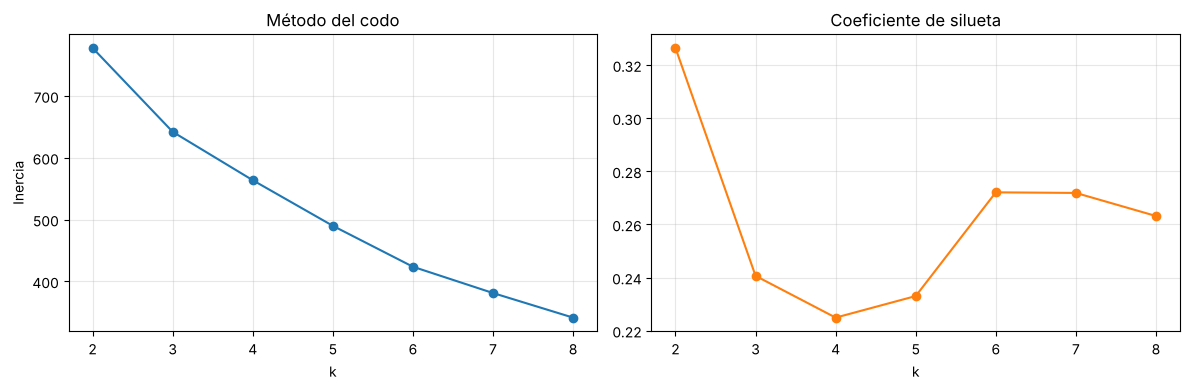

k = 2: silueta 0.326
k = 3: silueta 0.241
k = 4: silueta 0.225
k = 5: silueta 0.233
k = 6: silueta 0.272
k = 7: silueta 0.272
k = 8: silueta 0.263


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

columnas_modelo = ['exportaciones', 'salud', 'importaciones', 'ingresos', 'inflacion', 'expectativa', 'gdpp']
df_scaled = pd.DataFrame(StandardScaler().fit_transform(df_cleaned[columnas_modelo]),
                         columns=columnas_modelo, index=df_cleaned.index)

inercias, siluetas = [], []
rango_k = range(2, 9)
for k in rango_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10).fit(df_scaled)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(df_scaled, modelo.labels_))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(rango_k, inercias, 'o-')
ejes[0].set_title('Método del codo')
ejes[0].set_ylabel('Inercia')
ejes[1].plot(rango_k, siluetas, 'o-', color='tab:orange')
ejes[1].set_title('Coeficiente de silueta')
for eje in ejes:
    eje.set_xlabel('k')
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()
for k, s in zip(rango_k, siluetas):
    print(f'k = {k}: silueta {s:.3f}')

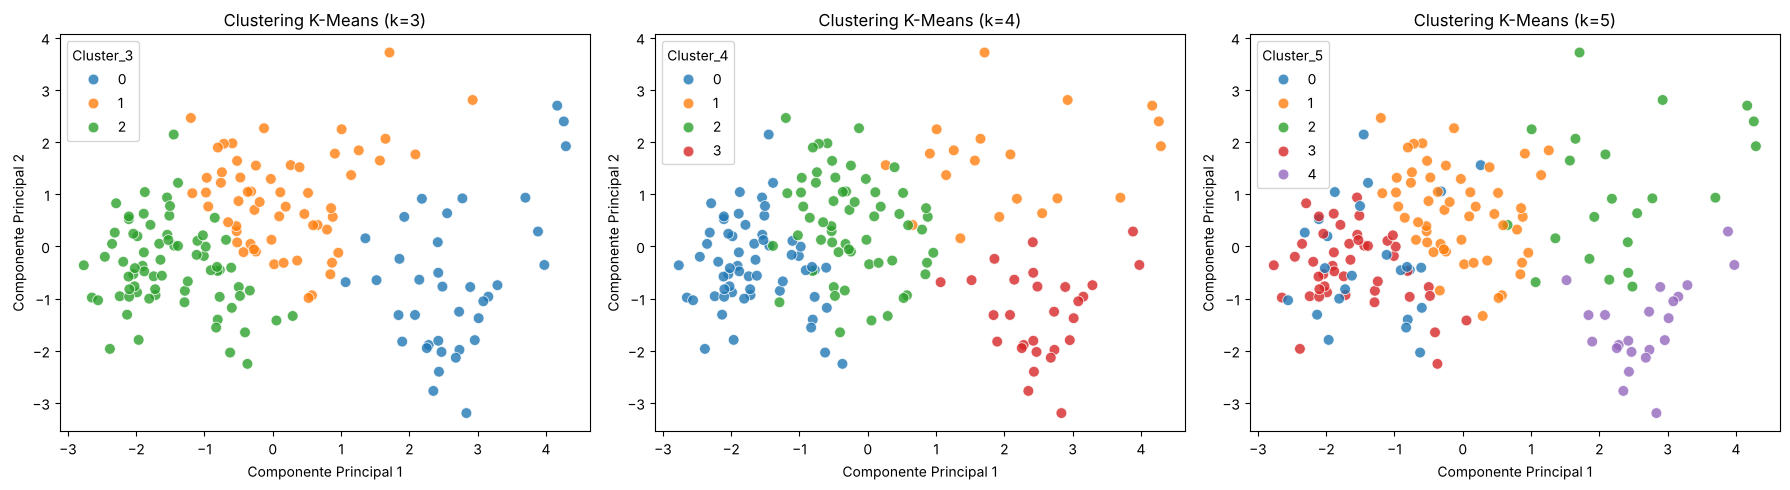


--- Promedios de las variables para k=4 ---


,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
Cluster_4,,,,,,,
0,27.04,5.50,33.81,5669.88,12.15,63.82,2619.00
1,78.37,6.44,72.74,31820.12,4.65,76.50,19525.00
2,38.57,7.21,54.14,9633.39,4.56,71.15,5212.27
3,40.64,8.95,35.04,39783.48,3.18,80.14,31196.43



--- Cantidad de países por cluster ---
Cluster_4
0    60
2    59
3    28
1    20
Name: count, dtype: int64


In [9]:
# PCA a 2 dimensiones solo para graficar los grupos
pca = PCA(n_components=2)
pca_data = pca.fit_transform(df_scaled)
df_pca = pd.DataFrame(pca_data, columns=['Dim1', 'Dim2'], index=df_cleaned.index)

# 3. Probar diferentes Ks (3, 4 y 5) y graficar
k_values = [3, 4, 5]
plt.figure(figsize=(18, 5))

for i, k in enumerate(k_values, 1):

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(df_scaled)

    # Guardamos los resultados
    df_pca[f'Cluster_{k}'] = clusters
    df_cleaned[f'Cluster_{k}'] = clusters

    # Graficar
    plt.subplot(1, 3, i)
    sns.scatterplot(x='Dim1', y='Dim2', hue=f'Cluster_{k}', palette='tab10', data=df_pca, s=60, alpha=0.8)
    plt.title(f'Clustering K-Means (k={k})')
    plt.xlabel('Componente Principal 1')
    plt.ylabel('Componente Principal 2')

plt.tight_layout()
plt.show()


k_elegido = 4
print(f"\n--- Promedios de las variables para k={k_elegido} ---")
analisis_clusters = df_cleaned.groupby(f'Cluster_{k_elegido}')[columnas_modelo].mean().round(2)
display(analisis_clusters)

# Ver cuántos países hay en cada cluster
print("\n--- Cantidad de países por cluster ---")
print(df_cleaned[f'Cluster_{k_elegido}'].value_counts())

In [10]:
# Análisis para K=3
k_elegido_3 = 3
print(f"\n--- Promedios de las variables para k={k_elegido_3} ---")
analisis_clusters_3 = df_cleaned.groupby(f'Cluster_{k_elegido_3}')[columnas_modelo].mean().round(2)
display(analisis_clusters_3)

print("\n--- Cantidad de países por cluster (k=3) ---")
print(df_cleaned[f'Cluster_{k_elegido_3}'].value_counts())


--- Promedios de las variables para k=3 ---


,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
Cluster_3,,,,,,,
0,49.61,8.40,43.97,40541.62,3.36,79.83,30333.78
1,49.22,7.08,61.68,12167.93,4.49,71.66,6658.98
2,26.58,5.74,34.10,6293.38,11.05,65.15,3056.85



--- Cantidad de países por cluster (k=3) ---
Cluster_3
2    72
1    58
0    37
Name: count, dtype: int64


In [11]:
# Análisis para K=5
k_elegido_5 = 5
print(f"\n--- Promedios de las variables para k={k_elegido_5} ---")
analisis_clusters_5 = df_cleaned.groupby(f'Cluster_{k_elegido_5}')[columnas_modelo].mean().round(2)
display(analisis_clusters_5)

print("\n--- Cantidad de países por cluster (k=5) ---")
print(df_cleaned[f'Cluster_{k_elegido_5}'].value_counts())


--- Promedios de las variables para k=5 ---


,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
Cluster_5,,,,,,,
0,38.83,5.21,34.45,10630.36,19.31,67.26,5008.48
1,42.93,7.31,57.98,10075.28,4.27,71.31,5534.17
2,73.38,5.78,63.82,37332.05,5.38,77.74,23536.82
3,21.13,5.85,34.63,4211.42,7.13,63.46,2009.36
4,36.02,10.27,34.65,38560.68,1.44,80.63,31905.00



--- Cantidad de países por cluster (k=5) ---
Cluster_5
1    53
3    45
0    25
4    22
2    22
Name: count, dtype: int64


In [12]:
print('Ejemplos de países por grupo (k = 4):')
for g, paises in df_cleaned.groupby('Cluster_4').groups.items():
    print(f'  Grupo {g} ({len(paises)}):', ', '.join(list(paises)[:10]), '…')

Ejemplos de países por grupo (k = 4):
  Grupo 0 (60): Afghanistan, Algeria, Angola, Argentina, Armenia, Azerbaijan, Bangladesh, Benin, Bolivia, Brazil …
  Grupo 1 (20): Bahrain, Belgium, Czech Republic, Equatorial Guinea, Estonia, Hungary, Ireland, Libya, Lithuania, Luxembourg …
  Grupo 2 (59): Albania, Antigua and Barbuda, Barbados, Belarus, Belize, Bhutan, Bosnia and Herzegovina, Botswana, Bulgaria, Cambodia …
  Grupo 3 (28): Australia, Austria, Bahamas, Brunei, Canada, Cyprus, Denmark, Finland, France, Germany …


**Elección de k.** La silueta es máxima con k = 2 (0,33), una partición que solo separa países ricos de pobres. Entre 3 y 5 grupos la silueta es parecida (0,22–0,24); se elige k = 4 porque distingue dos perfiles de países ricos que k = 3 mezcla, a costa de grupos menos compactos.

**Grupos con k = 4:**
- **Grupo 0, vulnerables (60 países):** la menor expectativa de vida (64 años), el menor PIB per cápita (unos 2.600) y la inflación más alta (12 %).
- **Grupo 2, ingreso medio (59 países):** indicadores intermedios, con expectativa de vida de 71 años e inflación de 4,6 %.
- **Grupo 3, desarrollados (28 países):** el mayor gasto en salud (9 % del PIB), la mayor expectativa de vida (80 años) y la inflación más baja.
- **Grupo 1, economías abiertas (20 países):** ricos (PIB per cápita de unos 19.500) y con exportaciones e importaciones que duplican las de los demás grupos.

## 4. Clustering jerárquico

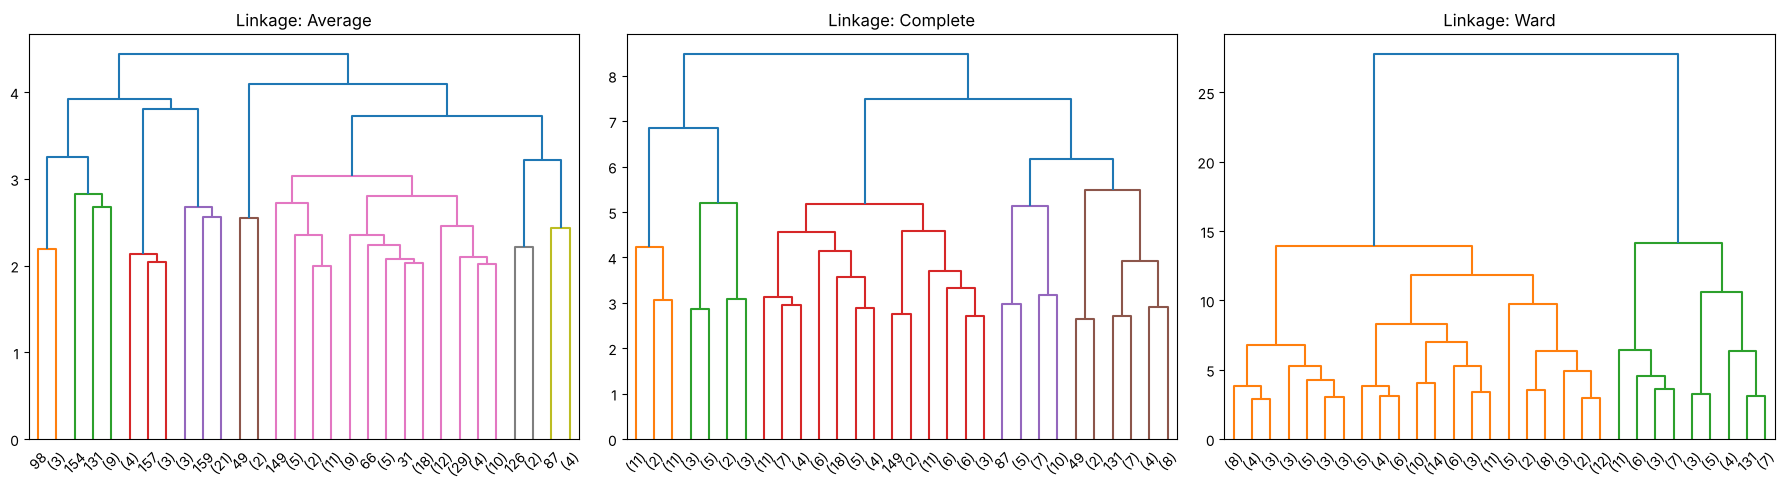

In [13]:
import scipy.cluster.hierarchy as shc
from sklearn.cluster import AgglomerativeClustering
# --- CLUSTERING JERÁRQUICO ---

# 1. Comparar métodos de linkage (Average, Complete, Ward)
metodos = ['average', 'complete', 'ward']
plt.figure(figsize=(18, 5))

for i, metodo in enumerate(metodos, 1):
    plt.subplot(1, 3, i)
    plt.title(f'Linkage: {metodo.capitalize()}')
    # Usamos df_scaled (los datos estandarizados del punto anterior)
    # truncate_mode='lastp' agrupa las hojas finales para que el gráfico no sea un desastre visual
    shc.dendrogram(shc.linkage(df_scaled, method=metodo), truncate_mode='lastp', p=30, show_leaf_counts=True)

plt.tight_layout()
plt.show()

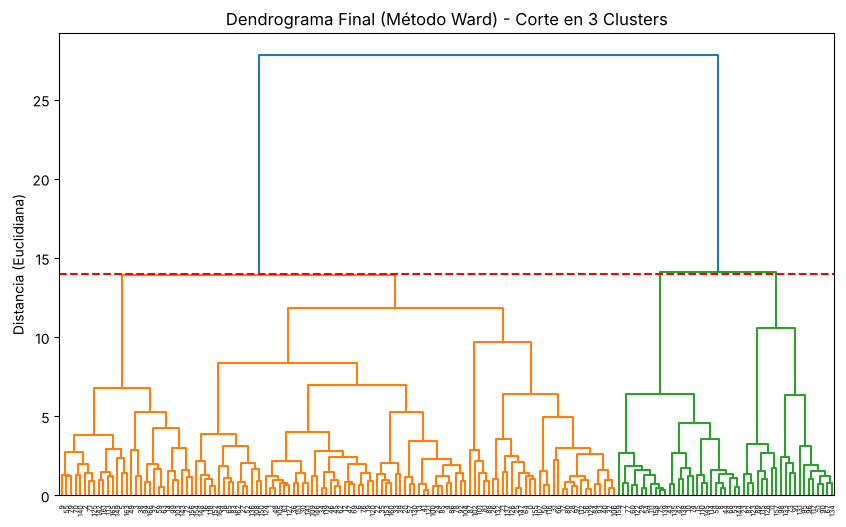


--- Promedios por Cluster Jerárquico (Ward, n=3) ---


,exportaciones,salud,importaciones,ingresos,inflacion,expectativa,gdpp
Cluster_Jerarquico,,,,,,,
0,33.20,6.33,44.02,7852.19,8.52,67.4,4014.70
1,76.04,5.39,65.53,35295.25,6.07,77.1,20788.00
2,40.69,9.89,39.50,37434.63,1.34,80.4,30782.96



Países por grupo:
  Grupo 0 (120): Afghanistan, Albania, Algeria, Angola, Antigua and Barbuda, Argentina, Armenia, Azerbaijan, Bangladesh, Barbados …
  Grupo 1 (20): Bahrain, Brunei, Estonia, Hungary, Ireland, Kuwait, Libya, Lithuania, Luxembourg, Malaysia …
  Grupo 2 (27): Australia, Austria, Bahamas, Belgium, Canada, Cyprus, Czech Republic, Denmark, Finland, France …


In [14]:
# 2. Dendrograma Final (Elegimos Ward)
# Ward es el mejor porque minimiza la varianza dentro de los grupos, creando clusters más equilibrados.
plt.figure(figsize=(10, 6))
plt.title("Dendrograma Final (Método Ward) - Corte en 3 Clusters")
# color_threshold define dónde se pinta de color distinto cada rama (nuestra línea de corte)
dend = shc.dendrogram(shc.linkage(df_scaled, method='ward'), color_threshold=20)
plt.axhline(y=14, color='r', linestyle='--') # Línea de corte visual
plt.ylabel('Distancia (Euclidiana)')
plt.show()

# 3. Extraer promedios para el modelo elegido (Corte en 3 clusters)
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
clusters_jerarquicos = hc.fit_predict(df_scaled)
df_cleaned['Cluster_Jerarquico'] = clusters_jerarquicos

print("\n--- Promedios por Cluster Jerárquico (Ward, n=3) ---")
display(df_cleaned.groupby('Cluster_Jerarquico')[columnas_modelo].mean().round(2))
print('\nPaíses por grupo:')
for g, paises in df_cleaned.groupby('Cluster_Jerarquico').groups.items():
    print(f'  Grupo {g} ({len(paises)}):', ', '.join(list(paises)[:10]), '…')

Se compararon los enlaces promedio, completo y de Ward. Ward genera los grupos más equilibrados porque en cada unión minimiza el aumento de la varianza interna; los otros dos tienden a dejar países aislados en grupos de uno.

Cortando el árbol en tres grupos:
- **Grupo 0 (120 países):** reúne a los países de ingreso bajo y medio: PIB per cápita promedio de unos 4.000, inflación de 8,5 % y expectativa de vida de 67 años. Es el grupo más amplio y heterogéneo.
- **Grupo 2 (27 países):** desarrollados estables: el mayor gasto en salud (9,9 %), la inflación más baja (1,3 %) y la mayor expectativa de vida (80 años).
- **Grupo 1 (20 países):** economías ricas y muy abiertas al comercio, con exportaciones del 76 % del PIB.

Frente a K-means con k = 4, Ward separa los mismos dos perfiles de países ricos, pero junta en un solo grupo a los vulnerables y a los de ingreso medio.

## 5. Componentes principales

--- Puntajes para los Componentes Principales (Loadings) ---


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
exportaciones,0.317,0.571,-0.324,0.106,-0.092,0.664,-0.083
salud,0.226,-0.198,0.647,0.629,0.080,0.294,0.051
importaciones,0.151,0.726,0.249,0.168,0.160,-0.578,0.004
ingresos,0.517,-0.148,-0.246,0.098,-0.300,-0.207,0.713
inflacion,-0.278,-0.088,-0.572,0.711,0.232,-0.160,-0.060
expectativa,0.459,-0.175,-0.120,-0.210,0.836,0.018,-0.025
gdpp,0.520,-0.218,-0.111,0.081,-0.342,-0.262,-0.691


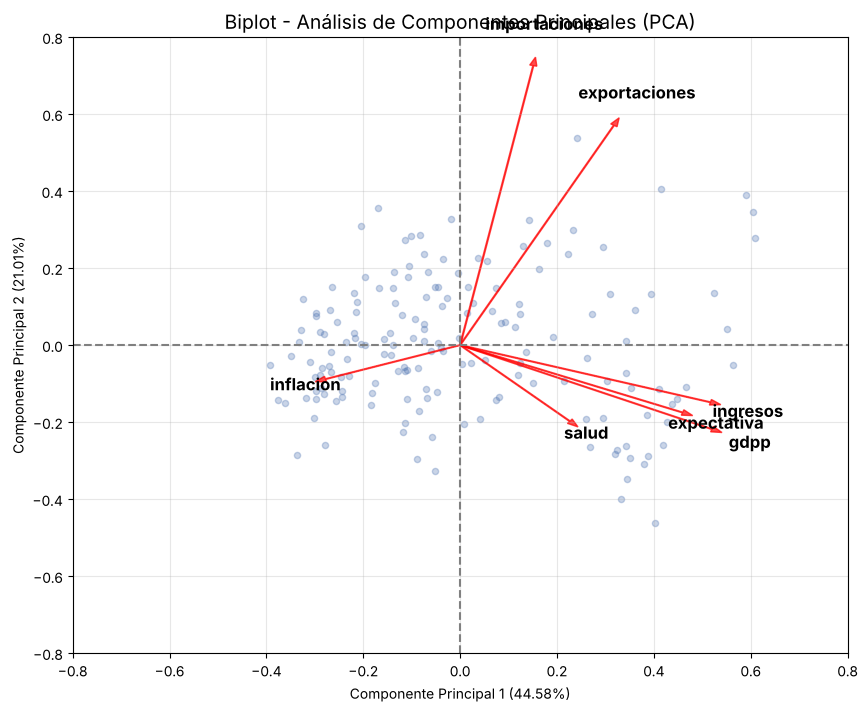

In [15]:
# 1. Puntajes (Loadings) de cada variable en los Componentes
pca_full = PCA()
pca_full.fit(df_scaled)

# Creamos un DataFrame para ver qué tanto pesa cada variable en cada componente (PC)
loadings = pd.DataFrame(pca_full.components_.T,
                        columns=[f'PC{i+1}' for i in range(len(columnas_modelo))],
                        index=columnas_modelo)

print("--- Puntajes para los Componentes Principales (Loadings) ---")
display(loadings.round(3))

# 2. Función para graficar el Biplot
def biplot(score, coeff, labels=None):
    xs = score[:,0]
    ys = score[:,1]
    n = coeff.shape[0]

    # Escalar para que los puntos y las flechas quepan en el mismo gráfico
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())

    plt.figure(figsize=(10, 8))
    plt.scatter(xs * scalex, ys * scaley, color='#4C72B0', alpha=0.3, s=20)

    for i in range(n):
        # Dibujar flechas
        plt.arrow(0, 0, coeff[i,0], coeff[i,1], color='red', alpha=0.7, width=0.002, head_width=0.015)
        # Poner nombres a las flechas
        if labels is not None:
            plt.text(coeff[i,0] * 1.15, coeff[i,1] * 1.15, labels[i], color='black',
                     ha='center', va='center', fontsize=12, fontweight='bold')

    plt.xlim(-0.8, 0.8)
    plt.ylim(-0.8, 0.8)
    # Las etiquetas muestran cuánta información (varianza) guarda cada componente
    plt.xlabel(f"Componente Principal 1 ({round(pca_full.explained_variance_ratio_[0]*100, 2)}%)")
    plt.ylabel(f"Componente Principal 2 ({round(pca_full.explained_variance_ratio_[1]*100, 2)}%)")
    plt.title("Biplot - Análisis de Componentes Principales (PCA)", fontsize=14)
    plt.axhline(0, color='gray', linestyle='--')
    plt.axvline(0, color='gray', linestyle='--')
    plt.grid(alpha=0.3)

# Aplicamos PCA de 2 dimensiones para el gráfico y llamamos la función
pca_2 = PCA(n_components=2)
x_new = pca_2.fit_transform(df_scaled)
biplot(x_new[:,0:2], pca_2.components_.T, labels=columnas_modelo)
plt.show()

**Componente 1 (riqueza y bienestar):** pesan casi por igual el PIB per cápita (0,52), los ingresos (0,52) y la expectativa de vida (0,46), y la inflación en sentido contrario (−0,28).

**Componente 2 (apertura comercial):** dominado por importaciones (0,73) y exportaciones (0,57).

**Biplot:** los vectores de ingresos y PIB per cápita casi se superponen, y los de comercio exterior son casi perpendiculares a ellos: comerciar mucho no implica ser más rico. La inflación apunta en sentido opuesto al grupo de riqueza y salud; es una asociación, no una prueba de que la inflación frene el desarrollo.